# Benchmark CP-SAT e Gurobi

Analisi delle serie già salvate in `results/`. Questo notebook non esegue i solver. Eseguire le celle in ordine con il kernel della `.venv`. Selezionare una o più serie nella cella seguente; per confronti omogenei, usare serie con lo stesso profilo scientifico.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "results"
# Vuoto = tutte le serie con entrambi i CSV; per selezionare: ["run_id_1", "run_id_2"].
RUN_IDS: list[str] = []

In [2]:
required_candidate_columns = {
    "run_id",
    "instance",
    "layout",
    "picks",
    "solver",
    "method",
    "dimension",
    "scan",
    "candidate_index",
    "depot_x",
    "depot_y",
    "status",
    "stop_reason",
    "total_cost_m",
    "solver_time_s",
    "candidate_time_s",
}
required_summary_columns = {
    "run_id",
    "instance",
    "layout",
    "picks",
    "solver",
    "method",
    "dimension",
    "job_status",
    "best_total_cost_m",
    "duration_s",
}
series = (
    sorted(
        path
        for path in RESULTS.iterdir()
        if path.is_dir()
        and (path / "candidati.csv").exists()
        and (path / "riepilogo.csv").exists()
    )
    if RESULTS.exists()
    else []
)
if RUN_IDS:
    unknown = set(RUN_IDS) - {path.name for path in series}
    if unknown:
        raise ValueError(f"Serie mancanti o incomplete: {sorted(unknown)}")
    series = [path for path in series if path.name in RUN_IDS]

candidate_parts = []
summary_parts = []
for path in series:
    candidates_part = pd.read_csv(path / "candidati.csv")
    summary_part = pd.read_csv(path / "riepilogo.csv")
    missing_candidates = required_candidate_columns - set(candidates_part.columns)
    missing_summary = required_summary_columns - set(summary_part.columns)
    if missing_candidates or missing_summary:
        raise ValueError(
            f"{path.name}: colonne mancanti: candidati={sorted(missing_candidates)}, "
            f"riepilogo={sorted(missing_summary)}"
        )
    if not candidates_part.empty and set(candidates_part["run_id"]) != {path.name}:
        raise ValueError(f"{path.name}: run_id incoerente in candidati.csv")
    if not summary_part.empty and set(summary_part["run_id"]) != {path.name}:
        raise ValueError(f"{path.name}: run_id incoerente in riepilogo.csv")
    candidate_parts.append(candidates_part)
    summary_parts.append(summary_part)

candidates = (
    pd.concat(candidate_parts, ignore_index=True) if candidate_parts else pd.DataFrame()
)
summary = (
    pd.concat(summary_parts, ignore_index=True) if summary_parts else pd.DataFrame()
)
print(
    f"Serie: {len(series)}; candidati tentati: {len(candidates)}; lavori: {len(summary)}"
)
if not series:
    print("Nessun risultato salvato. Eseguire `uv run python -m src.benchmark run`.")

Serie: 2; candidati tentati: 44; lavori: 4


## Stato e tempi

Le quote usano come denominatore i candidati tentati. Un timeout con incumbent è `FEASIBLE` e contribuisce alla quota con soluzione; un timeout senza soluzione non contribuisce ai costi. Le durate dei lavori usano i soli lavori conclusi.


In [3]:
if not candidates.empty:
    candidate_keys = ["run_id", "layout", "picks", "solver", "method", "dimension"]
    status_table = (
        candidates.assign(
            solved=candidates["status"].isin(["OPTIMAL", "FEASIBLE"]),
            optimal=candidates["status"].eq("OPTIMAL"),
            timeout_no_solution=candidates["status"].eq("TIME_LIMIT_NO_SOLUTION"),
            error=candidates["status"].eq("ERROR"),
        )
        .groupby(candidate_keys, dropna=False)
        .agg(
            attempted=("status", "size"),
            solution_share=("solved", "mean"),
            optimal_share=("optimal", "mean"),
            timeout_no_solution_share=("timeout_no_solution", "mean"),
            error_share=("error", "mean"),
            median_solver_s=("solver_time_s", "median"),
            p90_solver_s=("solver_time_s", lambda values: values.quantile(0.9)),
            median_candidate_s=("candidate_time_s", "median"),
        )
        .reset_index()
    )
    display(status_table)
    display(
        pd.crosstab([candidates["run_id"], candidates["solver"]], candidates["status"])
    )
    display(
        pd.crosstab(
            [candidates["solver"], candidates["stop_reason"]], columns="candidati"
        )
    )
else:
    status_table = pd.DataFrame()

if not summary.empty:
    completed = summary.loc[summary["job_status"].eq("COMPLETE")].copy()
    if not completed.empty:
        display(
            completed.groupby(["run_id", "solver", "method", "dimension"], dropna=False)
            .agg(
                completed_jobs=("instance", "size"),
                median_job_s=("duration_s", "median"),
                p90_job_s=("duration_s", lambda values: values.quantile(0.9)),
            )
            .reset_index()
        )
    display(
        summary.groupby(["run_id", "job_status"], dropna=False)
        .agg(jobs=("instance", "size"))
        .reset_index()
    )

,run_id,layout,picks,solver,method,dimension,attempted,solution_share,optimal_share,timeout_no_solution_share,error_share,median_solver_s,p90_solver_s,median_candidate_s
0,52f2707349e6ec70,9x4,10,cp_sat,Basic,1d,11,1.0,1.0,0.0,0.0,0.036495,0.087844,0.038338
1,52f2707349e6ec70,9x4,10,gurobi,Basic,1d,11,1.0,1.0,0.0,0.0,0.001509,0.009115,0.002270
2,c7ee9da56816c5c6,9x4,10,cp_sat,Basic,1d,11,1.0,1.0,0.0,0.0,0.035521,0.053983,0.037175
3,c7ee9da56816c5c6,9x4,10,gurobi,Basic,1d,11,1.0,1.0,0.0,0.0,0.001366,0.002975,0.002018


status                   OPTIMAL
run_id           solver         
52f2707349e6ec70 cp_sat       11
                 gurobi       11
c7ee9da56816c5c6 cp_sat       11
                 gurobi       11

,col_0
solver,stop_reason


,run_id,solver,method,dimension,completed_jobs,median_job_s,p90_job_s
0,52f2707349e6ec70,cp_sat,Basic,1d,1,0.545811,0.545811
1,52f2707349e6ec70,gurobi,Basic,1d,1,0.146461,0.146461
2,c7ee9da56816c5c6,cp_sat,Basic,1d,1,0.491170,0.491170
3,c7ee9da56816c5c6,gurobi,Basic,1d,1,0.082644,0.082644


,run_id,job_status,jobs
0,52f2707349e6ec70,COMPLETE,2
1,c7ee9da56816c5c6,COMPLETE,2


## Confronto per deposito

Per Basic il confronto usa solo coppie della stessa serie, istanza, dimensione e coordinate, con soluzione da entrambi. Per ZoomIn le scansioni successive possono divergere: la tabella delle visite segnala i depositi valutati da un solo solver; l'abbinamento per deposito usa solo l'intersezione.


In [4]:
import json

series_times = []
for path in series:
    config_path = path / "config.json"
    if config_path.exists():
        config = json.loads(config_path.read_text())
        series_times.append(
            {
                "run_id": path.name,
                "total_wall_seconds": config.get("total_wall_seconds"),
                "finished_at": config.get("finished_at"),
            }
        )
if series_times:
    display(pd.DataFrame(series_times))

,run_id,total_wall_seconds,finished_at
0,52f2707349e6ec70,1.255810,2026-11-14T13:52:26.007668+00:00
1,c7ee9da56816c5c6,1.073978,2026-11-14T13:55:21.105384+00:00


In [5]:
if not candidates.empty:
    visit_keys = ["run_id", "instance", "method", "dimension", "depot_x", "depot_y"]
    visits = candidates.loc[:, [*visit_keys, "solver", "status", "total_cost_m"]].copy()
    visits["solved"] = visits["status"].isin(["OPTIMAL", "FEASIBLE"])
    visits = visits.drop_duplicates([*visit_keys, "solver"])
    paired_visits = visits.pivot(
        index=visit_keys, columns="solver", values=["solved", "total_cost_m"]
    )
    paired_visits.columns = [
        f"{field}_{solver}" for field, solver in paired_visits.columns
    ]
    paired_visits = paired_visits.reset_index()
    if {"solved_cp_sat", "solved_gurobi"}.issubset(paired_visits.columns):
        paired_visits["visit_type"] = "both"
        paired_visits.loc[paired_visits["solved_cp_sat"].isna(), "visit_type"] = (
            "only_gurobi"
        )
        paired_visits.loc[paired_visits["solved_gurobi"].isna(), "visit_type"] = (
            "only_cp_sat"
        )
        display(
            paired_visits.groupby(["run_id", "method", "dimension", "visit_type"])
            .size()
            .reset_index(name="depots")
        )
        both_solved = paired_visits.loc[
            paired_visits["solved_cp_sat"].eq(True)
            & paired_visits["solved_gurobi"].eq(True)
        ].copy()
        both_solved["delta_gurobi_minus_cp_sat_m"] = (
            both_solved["total_cost_m_gurobi"] - both_solved["total_cost_m_cp_sat"]
        )
        display(
            both_solved.groupby(["run_id", "method", "dimension"])
            .agg(
                paired_depots=("instance", "size"),
                median_delta_m=("delta_gurobi_minus_cp_sat_m", "median"),
                max_abs_delta_m=(
                    "delta_gurobi_minus_cp_sat_m",
                    lambda values: values.abs().max(),
                ),
            )
            .reset_index()
        )
    else:
        print("Per confrontare i depositi servono risultati di entrambi i solver.")
else:
    paired_visits = pd.DataFrame()

,run_id,method,dimension,visit_type,depots
0,52f2707349e6ec70,Basic,1d,both,11
1,c7ee9da56816c5c6,Basic,1d,both,11


,run_id,method,dimension,paired_depots,median_delta_m,max_abs_delta_m
0,52f2707349e6ec70,Basic,1d,11,0.0,0.0
1,c7ee9da56816c5c6,Basic,1d,11,0.0,0.0


## Miglior costo per istanza

Si confrontano solo i lavori della stessa serie, istanza, metodo e dimensione con un migliore disponibile da entrambi i solver. La coincidenza dei costi euclidei entro `1e-6` m non costituisce una prova di ottimalità.


In [6]:
if not summary.empty:
    final_keys = ["run_id", "instance", "layout", "picks", "method", "dimension"]
    best = summary.loc[:, [*final_keys, "solver", "best_total_cost_m"]].copy()
    best = best.pivot(
        index=final_keys, columns="solver", values="best_total_cost_m"
    ).reset_index()
    if {"cp_sat", "gurobi"}.issubset(best.columns):
        best["availability"] = "both"
        best.loc[best["cp_sat"].isna(), "availability"] = "only_gurobi"
        best.loc[best["gurobi"].isna(), "availability"] = "only_cp_sat"
        best.loc[best[["cp_sat", "gurobi"]].isna().all(axis=1), "availability"] = (
            "neither"
        )
        display(
            best.groupby(["run_id", "method", "dimension", "availability"])
            .size()
            .reset_index(name="instances")
        )
        matched_best = best.loc[best["availability"].eq("both")].copy()
        matched_best["delta_gurobi_minus_cp_sat_m"] = (
            matched_best["gurobi"] - matched_best["cp_sat"]
        )
        matched_best["same_cost_1e_6_m"] = (
            matched_best["delta_gurobi_minus_cp_sat_m"].abs().le(1e-6)
        )
        display(
            matched_best.groupby(["run_id", "layout", "picks", "method", "dimension"])
            .agg(
                paired_instances=("instance", "size"),
                median_delta_m=("delta_gurobi_minus_cp_sat_m", "median"),
                same_cost_share=("same_cost_1e_6_m", "mean"),
            )
            .reset_index()
        )
    else:
        print(
            "Per confrontare i migliori costi servono risultati di entrambi i solver."
        )
else:
    matched_best = pd.DataFrame()

,run_id,method,dimension,availability,instances
0,52f2707349e6ec70,Basic,1d,both,1
1,c7ee9da56816c5c6,Basic,1d,both,1


,run_id,layout,picks,method,dimension,paired_instances,median_delta_m,same_cost_share
0,52f2707349e6ec70,9x4,10,Basic,1d,1,0.0,1.0
1,c7ee9da56816c5c6,9x4,10,Basic,1d,1,0.0,1.0


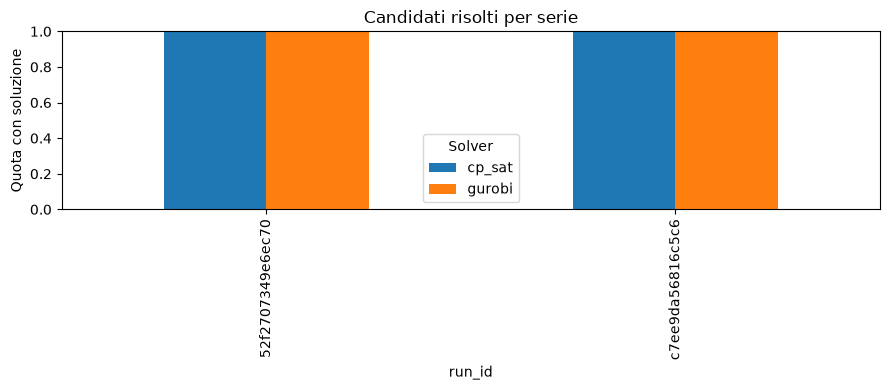

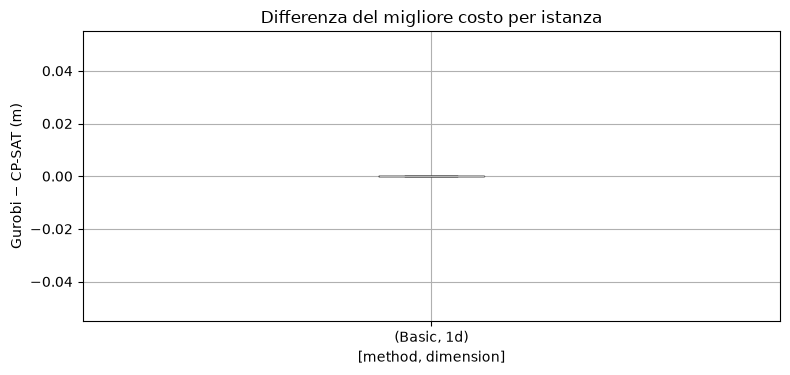

In [7]:
if not status_table.empty:
    plot_data = status_table.groupby(["run_id", "solver"], as_index=False).agg(
        attempted=("attempted", "sum"),
        solved_weighted=("solution_share", lambda values: 0.0),
    )
    solved_counts = (
        candidates.assign(solved=candidates["status"].isin(["OPTIMAL", "FEASIBLE"]))
        .groupby(["run_id", "solver"], as_index=False)["solved"]
        .sum()
    )
    plot_data = plot_data.drop(columns="solved_weighted").merge(
        solved_counts, on=["run_id", "solver"]
    )
    plot_data["solution_share"] = plot_data["solved"] / plot_data["attempted"]
    ax = plot_data.pivot(
        index="run_id", columns="solver", values="solution_share"
    ).plot.bar(
        figsize=(9, 4),
        ylim=(0, 1),
        ylabel="Quota con soluzione",
        title="Candidati risolti per serie",
    )
    ax.legend(title="Solver")
    plt.tight_layout()
    plt.show()

if not matched_best.empty:
    ax = matched_best.boxplot(
        column="delta_gurobi_minus_cp_sat_m", by=["method", "dimension"], figsize=(8, 4)
    )
    ax.set_title("Differenza del migliore costo per istanza")
    ax.set_ylabel("Gurobi − CP-SAT (m)")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()